# L1: quantitatively selected refraction tomography

This analysis does not force horizontal layers or infer lithology from a football-field setting. It compares 24 isotropically smoothed models using three-fold held-out traveltime prediction, retains all 60 automatic picks, and fits a homogeneous starting velocity estimated only from each training set. Model depth and lambda are selected jointly. The lambda range was expanded after the initial nine-model search selected its lower boundary.

**Not assumption-free:** the same automatic picking limits as the earlier notebook are retained to isolate inversion effects. Surface elevation is unmeasured and held at zero; subsurface structure is free to vary laterally. The 47.5 m source override remains conditional on field verification. Held-out error evaluates consistency with these picks, not their correctness. Interleaved source/receiver pairs (including reciprocal grouping) measure interpolation, not independent-line or new-shot performance. Selection CV is optimistic after choosing among candidates; no independent test survey is available.

/home/orincon/miniconda3/envs/refrapy-l1/bin/python 
pyGIMLi 1.5.5
Read 5 shot gathers from L1/RF:
  2026-10-08_RF_-5m.dat: source at -5.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_12.5m.dat: source at +12.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_27.5m.dat: source at +27.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_47.5m.dat: source at +47.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_60m.dat: source at +60.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
Traveltime data: 17 sensors, 60 picks


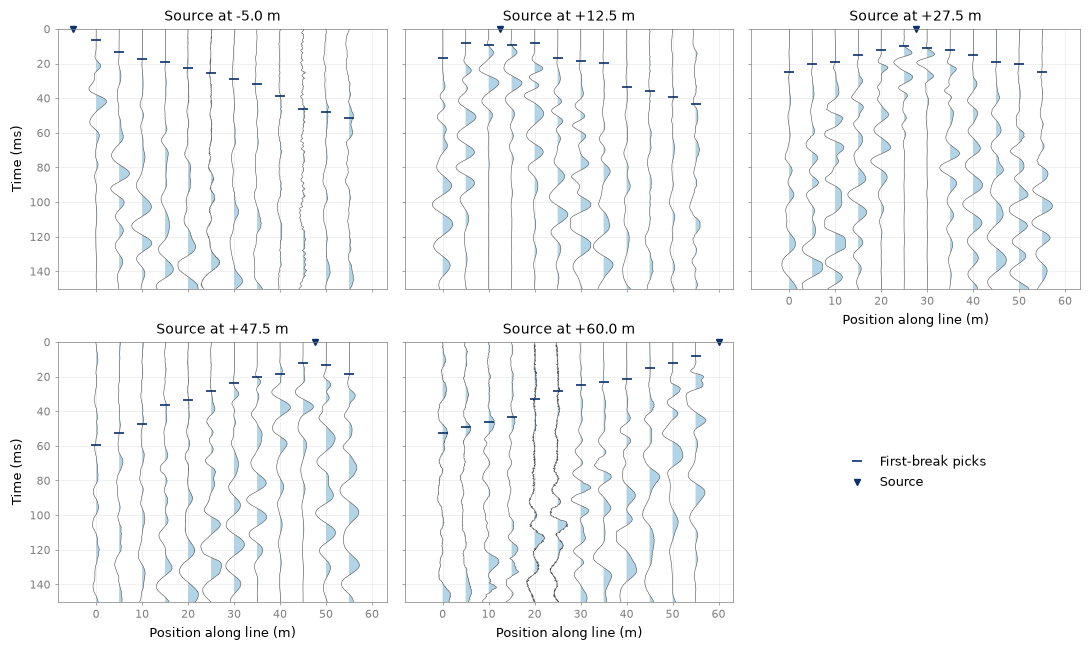

In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pygimli as pg
from IPython.display import display
from utils import seg2_io, refraction, plotting
from utils.tomography_selection import select_model

OUTPUT = Path('L1/optimized_inversion')
SOURCE_OVERRIDES = {'2026-10-08_RF_47.5m.dat': 47.5}
DEPTHS = (8.0, 12.0, 18.0)
LAMBDAS = (0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 300.0)
N_FOLDS, MAX_ITER = 3, 12
PICK_ERROR = 0.0035
print(sys.executable, '\npyGIMLi', pg.__version__)
gathers = seg2_io.read_line('L1/RF', source_x_overrides=SOURCE_OVERRIDES)
picks = refraction.pick_line(gathers, v_min=150, v_max=1500, noise_window=0.010, threshold=3.0)
data = refraction.build_traveltime_data(gathers, picks, pick_error=PICK_ERROR)
plotting.plot_all_gathers(gathers, picks_per_shot=picks, t_max=0.15, width=11, fontsize=9)
plt.show()

In [2]:
manager, ranking, fit = select_model(data, depths=DEPTHS, lambdas=LAMBDAS,
                                     n_folds=N_FOLDS, max_iter=MAX_ITER)
display(ranking)
best = ranking.iloc[0]
metrics = pd.DataFrame([dict(
    picks=len(fit), selected_depth_m=best.depth_m, selected_lambda=best.lam,
    training_rms_ms=np.sqrt(np.mean(fit.residual_ms ** 2)),
    selection_cv_rms_ms=np.sqrt(np.mean(fit.held_out_residual_ms ** 2)),
    training_relative_rms_percent=100*np.sqrt(np.mean((fit.residual_ms/fit.observed_ms)**2)),
    chi_squared=manager.inv.chi2(),
    vp_min_m_s=np.min(manager.velocity), vp_max_m_s=np.max(manager.velocity))])
display(metrics)
if best.depth_m in (min(DEPTHS), max(DEPTHS)) or best.lam in (min(LAMBDAS), max(LAMBDAS)):
    print('CAUTION: selected parameters touch the search boundary; this is not a global optimum.')
print('No picks were rejected. Lower training RMS alone is not the selection criterion.')

24/10/26 - 18:43:12 - pyGIMLi - INFO - Found 1 regions.


24/10/26 - 18:43:12 - pyGIMLi - INFO - Found 1 regions.


24/10/26 - 18:43:12 - pyGIMLi - INFO - Creating forward mesh from region infos.


24/10/26 - 18:43:12 - pyGIMLi - INFO - Creating refined mesh (secnodes: 2) to solve forward task.


24/10/26 - 18:43:12 - pyGIMLi - INFO - Create gradient starting model. 951.0797874345154: 951.0797874345154


...

24/10/26 - 18:46:18 - pyGIMLi - INFO - Create gradient starting model. 899.1500829187396: 899.1500829187396


24/10/26 - 18:46:20 - pyGIMLi - INFO - Creating refined mesh (secnodes: 2) to solve forward task.


,depth_m,lam,cv_rms_ms,cv_mae_ms,fold_rms_min_ms,fold_rms_max_ms
0,8.0,0.30,3.713567,2.962429,3.204442,4.075417
1,12.0,1.00,3.743540,2.960081,3.384127,3.920167
2,8.0,0.10,3.744634,2.978021,3.155032,4.049762
3,18.0,1.00,3.754667,2.955955,3.376813,3.979661
4,8.0,1.00,3.766089,2.953185,3.069743,4.194941
5,8.0,3.00,3.831194,3.055083,3.478767,4.033401
6,12.0,0.10,3.873510,3.116114,3.222461,4.335720
7,12.0,3.00,3.893836,3.163433,3.206399,4.351643
8,8.0,0.03,3.910081,3.183878,2.967139,4.466817
9,18.0,0.30,3.920503,3.123414,3.384651,4.456362


,picks,selected_depth_m,selected_lambda,training_rms_ms,selection_cv_rms_ms,training_relative_rms_percent,chi_squared,vp_min_m_s,vp_max_m_s
0,60,8.0,0.3,2.376675,3.713567,14.806793,0.461109,143.113703,1915.645272


CAUTION: selected parameters touch the search boundary; this is not a global optimum.
No picks were rejected. Lower training RMS alone is not the selection criterion.


## Predicted curves relative to observations
Solid curves are the selected model fitted to all observations. Dashed curves are out-of-fold predictions: each arrival was predicted without fitting it. These dashed points come from three different training models, not a single model. Residuals are observed minus predicted.

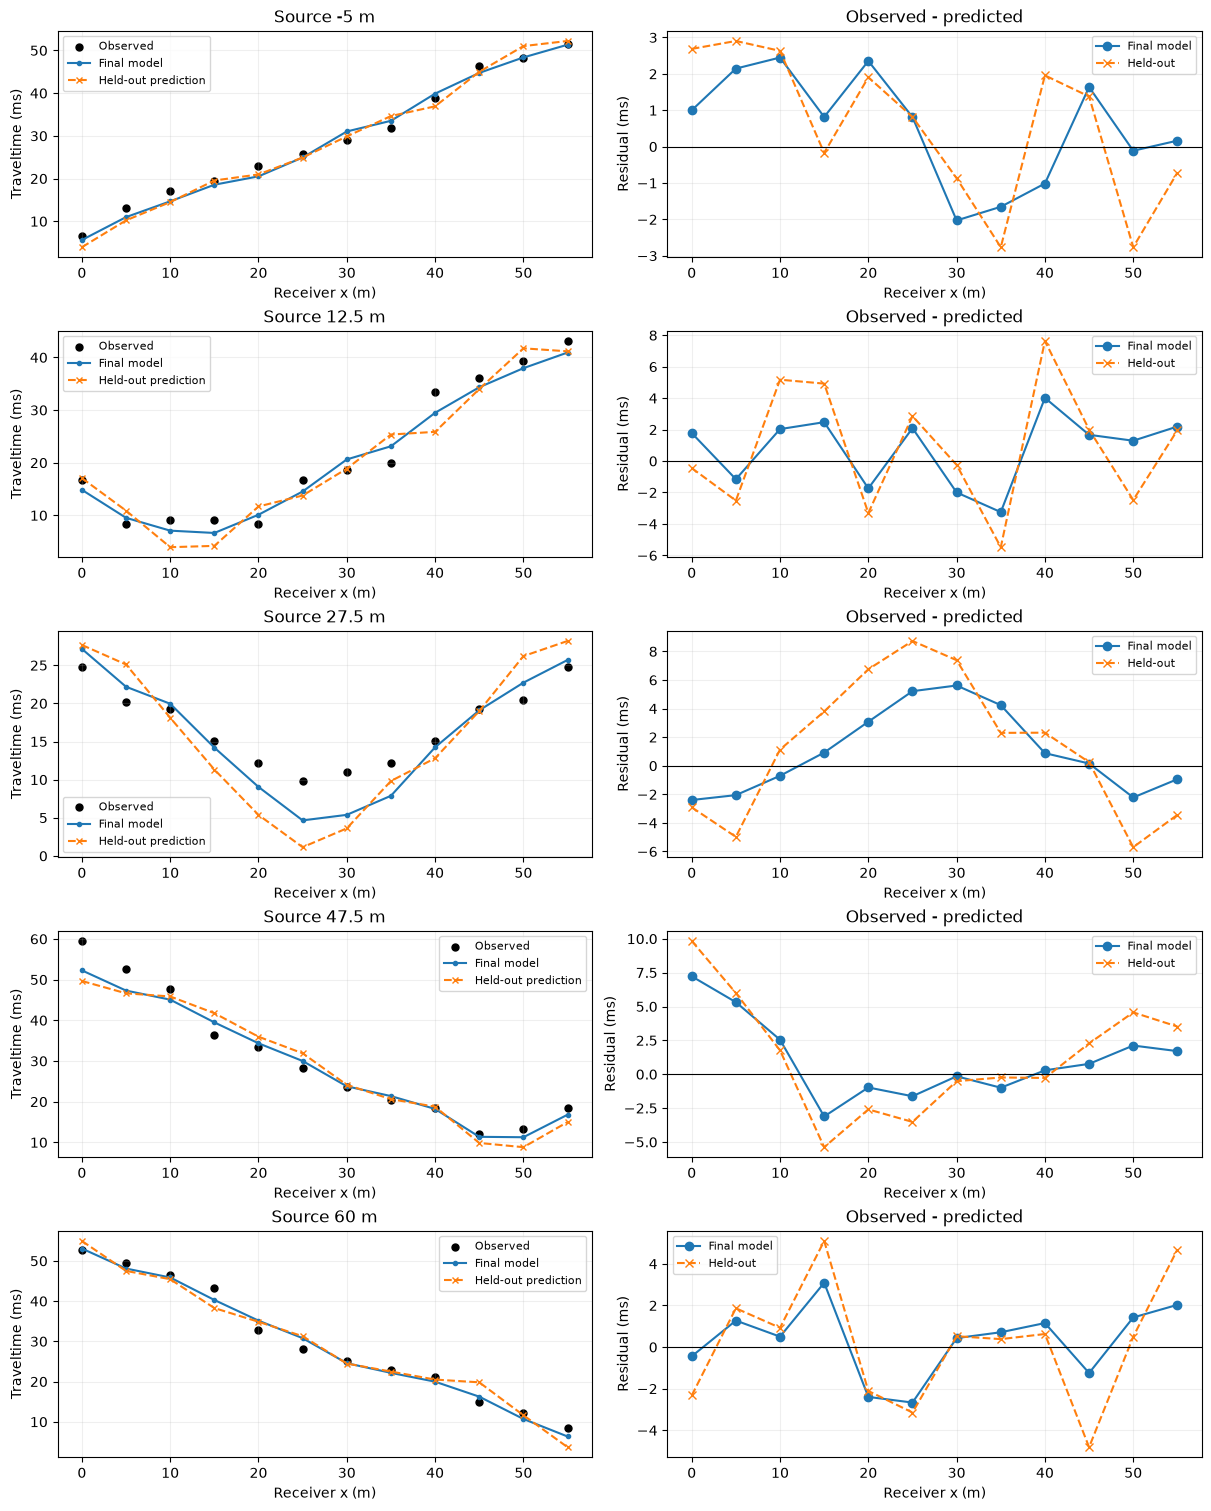

,picks,training_rms_ms,held_out_rms_ms
source_x_m,,,
-5.0,12,1.556295,2.024548
12.5,12,2.274977,3.863090
27.5,12,2.946353,4.832799
47.5,12,3.019141,4.307245
60.0,12,1.687943,2.832373


In [3]:
curve_figure, axes = plt.subplots(len(gathers), 2, figsize=(12, 3*len(gathers)), squeeze=False, constrained_layout=True)
for row, (source, group) in enumerate(fit.groupby('source_x_m', sort=True)):
    group = group.sort_values('receiver_x_m')
    ax, residual_ax = axes[row]
    ax.scatter(group.receiver_x_m, group.observed_ms, color='black', s=25, label='Observed')
    ax.plot(group.receiver_x_m, group.predicted_ms, 'o-', ms=3, label='Final model')
    ax.plot(group.receiver_x_m, group.held_out_ms, 'x--', ms=4, label='Held-out prediction')
    ax.set(title=f'Source {source:g} m', ylabel='Traveltime (ms)', xlabel='Receiver x (m)')
    residual_ax.plot(group.receiver_x_m, group.residual_ms, 'o-', label='Final model')
    residual_ax.plot(group.receiver_x_m, group.held_out_residual_ms, 'x--', label='Held-out')
    residual_ax.axhline(0, color='black', lw=0.8)
    residual_ax.set(title='Observed - predicted', ylabel='Residual (ms)', xlabel='Receiver x (m)')
    for panel in (ax, residual_ax):
        panel.grid(alpha=0.2)
        panel.legend(fontsize=8)
plt.show()
display(fit.groupby('source_x_m').agg(
    picks=('residual_ms','size'),
    training_rms_ms=('residual_ms', lambda r: np.sqrt(np.mean(r**2))),
    held_out_rms_ms=('held_out_residual_ms', lambda r: np.sqrt(np.mean(r**2)))))

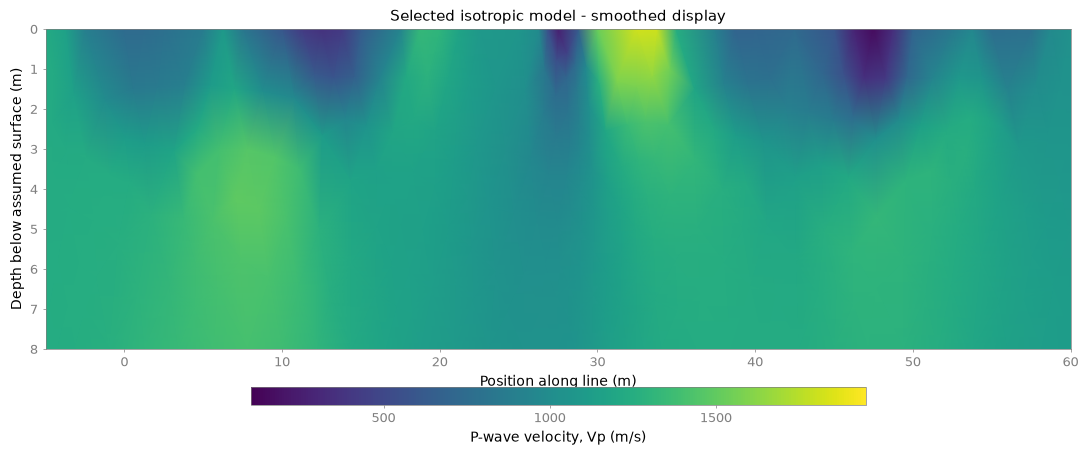

Display interpolation only; inversion values are unchanged. No additional resolution is implied.
Model extent is not investigation depth. Unilluminated cells are weakly constrained.


In [ ]:
ax, cbar = plotting.plot_tomogram(manager, width=11, height=4.5, fontsize=10,
                                 rays=False, show_mesh=False, smooth=True, xlim=(-5,60),
                                 cbar_thickness=0.18, cbar_label='P-wave velocity, Vp (m/s)',
                                 ylabel='Depth below assumed surface (m)',
                                 title='Selected isotropic model - smoothed display')
from matplotlib.ticker import FuncFormatter
ax.set_ylim(manager.paraDomain.yMin(), 0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{abs(value):g}'))
model_figure = ax.figure
plt.show()
print('Display interpolation only; inversion values are unchanged. No additional resolution is implied.')
print('Model extent is not investigation depth. Unilluminated cells are weakly constrained.')

## Interpretation limits
Depth, lambda, mesh and picks still constrain the result. No 80 m horizontal correlation, velocity-with-depth prior or model-dependent pick rejection is used here. The 3.5 ms uncertainty is an assumed weighting scale, not an independently calibrated measurement. With 5 m receiver spacing, shallow construction layers are not resolved reliably. Prediction error cannot establish lithology, saturation or compaction. Compare models on the same observations: the earlier 57-pick RMS is not directly comparable to this all-60-pick fit.

In [5]:
OUTPUT.mkdir(parents=True, exist_ok=True)
ranking.to_csv(OUTPUT/'candidate_ranking.csv', index=False)
fit.to_csv(OUTPUT/'observed_predicted.csv', index=False)
metrics.to_csv(OUTPUT/'summary.csv', index=False)
curve_figure.savefig(OUTPUT/'prediction_curves.png', dpi=160, bbox_inches='tight')
model_figure.savefig(OUTPUT/'velocity_model.png', dpi=180, bbox_inches='tight')
manager.paraDomain.save(str(OUTPUT/'mesh.bms'))
np.save(OUTPUT/'velocity.npy', np.asarray(manager.velocity))
refraction.export_refrapy_picks(data, OUTPUT/'all_picks.sgt')
settings = dict(depths=DEPTHS, lambdas=LAMBDAS, folds=N_FOLDS, max_iter=MAX_ITER,
                source_overrides=SOURCE_OVERRIDES, z_weight=1.0, pick_error_s=PICK_ERROR,
                picking=dict(v_min=150, v_max=1500, noise_window=0.010, threshold=3.0),
                start_model='homogeneous training median apparent velocity',
                mesh=dict(para_dx=0.5, max_cell_size=2.0, para_boundary=0.5),
                python=sys.version, pygimli=pg.__version__, numpy=np.__version__,
                status='Preliminary automatic picks; search-selection CV, not independent test error')
(OUTPUT/'settings.json').write_text(json.dumps(settings, indent=2)+'\n')
print('Saved:', OUTPUT.resolve())

Saved: /home/orincon/seismic-refraction-analysis/L1/optimized_inversion
